In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import os
import glob
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
import random

In [2]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5, img_channels=3):
        super(Generator, self).__init__()
        self.num_classes = num_classes
        self.latent_dim = latent_dim
        
        self.init_size = 16
        self.label_embedding = nn.Embedding(num_classes, latent_dim)
        
        self.l1 = nn.Sequential(nn.Linear(latent_dim * 2, 128 * self.init_size ** 2))
        
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 128, 3, stride=1, padding=1),
            nn.BatchNorm2d(128, 0.8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.1),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, stride=1, padding=1),
            nn.BatchNorm2d(64, 0.8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, img_channels, 3, stride=1, padding=1),
            nn.Tanh()
        )
    
    def forward(self, z, labels):
        label_embed = self.label_embedding(labels)
        gen_input = torch.cat((label_embed, z), -1)
        
        out = self.l1(gen_input)
        out = out.view(out.shape[0], 128, self.init_size, self.init_size)
        img = self.conv_blocks(out)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes=5, img_channels=3):
        super(Discriminator, self).__init__()
        
        def discriminator_block(in_filters, out_filters, bn=True):
            block = [nn.Conv2d(in_filters, out_filters, 3, 2, 1),
                    nn.LeakyReLU(0.2, inplace=True),
                    nn.Dropout2d(0.3)]
            if bn:
                block.append(nn.BatchNorm2d(out_filters, 0.8))
            return block
        
        self.model = nn.Sequential(
            *discriminator_block(img_channels, 16, bn=False),
            *discriminator_block(16, 32),
            *discriminator_block(32, 64),
            *discriminator_block(64, 128),
        )
        
        ds_size = 64 // 2 ** 4
        self.adv_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, 1), nn.Sigmoid())
        self.aux_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, num_classes), nn.Softmax(dim=1))
    
    def forward(self, img):
        out = self.model(img)
        out = out.view(out.shape[0], -1)
        validity = self.adv_layer(out)
        label = self.aux_layer(out)
        return validity, label

In [ ]:
class ACGANDataset(Dataset):
    def __init__(self, normal_folder, defect_folders, transform=None, img_size=64):
        self.transform = transform
        self.img_size = img_size
        self.image_paths = []
        self.labels = []
        
        self.class_names = ['normal', 'abrasive', 'adhesive', 'cracks', 'delamination']
        
        normal_images = self._get_image_paths(normal_folder)
        self.image_paths.extend(normal_images)
        self.labels.extend([0] * len(normal_images))
        
        for i, defect_folder in enumerate(defect_folders, 1):
            defect_images = self._get_image_paths(defect_folder)
            self.image_paths.extend(defect_images)
            self.labels.extend([i] * len(defect_images))
    
    def _get_image_paths(self, folder_path):
        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG', '*.BMP']
        image_paths = []
        
        for extension in extensions:
            image_paths.extend(glob.glob(os.path.join(folder_path, extension)))
        
        return image_paths
        
    def __len__(self):
        return len(self.image_paths)
        
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        try:
            image = Image.open(img_path).convert('RGB')
            
            if self.transform:
                image = self.transform(image)
            else:
                transform = transforms.Compose([
                    transforms.Resize((self.img_size, self.img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize([0.5] * 3, [0.5] * 3)
                ])
                image = transform(image)
                
            return image, label
            
        except Exception as e:
            print(f"Downloading Error {img_path}: {e}")
            dummy_image = torch.zeros(3, self.img_size, self.img_size)
            return dummy_image, label

In [ ]:
class ACGANAnomalyDetection:
    def __init__(self, num_classes=5, img_size=64, channels=3, latent_dim=100):
        self.num_classes = num_classes
        self.img_size = img_size
        self.channels = channels
        self.latent_dim = latent_dim
        
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        
        self.generator = Generator(latent_dim, num_classes, channels).to(self.device)
        self.discriminator = Discriminator(num_classes, channels).to(self.device)
        
        self.adversarial_loss = nn.BCELoss()
        self.auxiliary_loss = nn.CrossEntropyLoss()
        
        self.optimizer_G = optim.Adam(self.generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
        self.optimizer_D = optim.Adam(self.discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
        
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * channels, [0.5] * channels)
        ])
        
        self.class_names = ['normal', 'abrasive', 'adhesive', 'cracks', 'delamination']

        self.history={'g_loss': [], 'g_adv': [], 'g_aux': [],
                      'd_loss': [], 'd_adv': [], 'd_aux': []}
    
    def train(self, dataloader, epochs):
        self.generator.train()
        self.discriminator.train()
        
        for epoch in range(epochs):
            epoch_g_loss = 0.0
            epoch_g_adv  = 0.0
            epoch_g_aux  = 0.0
            epoch_d_loss = 0.0
            epoch_d_adv  = 0.0
            epoch_d_aux  = 0.0
            
            for i, (imgs, labels) in enumerate(dataloader):
                batch_size = imgs.size(0)
                real_imgs = imgs.to(self.device)
                real_labels = labels.to(self.device)
                
                valid = torch.ones(batch_size, 1, device=self.device)
                fake = torch.zeros(batch_size, 1, device=self.device)
                
                self.optimizer_G.zero_grad()
                
                gen_labels = torch.randint(0, self.num_classes, (batch_size,), device=self.device)
                z = torch.randn(batch_size, self.latent_dim, device=self.device)
                
                gen_imgs = self.generator(z, gen_labels)
                
                validity, pred_label = self.discriminator(gen_imgs)
                g_loss_adv = self.adversarial_loss(validity, valid)
                g_loss_aux = self.auxiliary_loss(pred_label, gen_labels)
                g_loss = g_loss_adv + g_loss_aux
                
                g_loss.backward()
                self.optimizer_G.step()
                
                self.optimizer_D.zero_grad()

                real_validity, real_pred_label = self.discriminator(real_imgs)
                d_real_loss_adv = self.adversarial_loss(real_validity, valid)
                d_real_loss_aux = self.auxiliary_loss(real_pred_label, real_labels)

                fake_validity, fake_pred_label = self.discriminator(gen_imgs.detach())
                d_fake_loss_adv = self.adversarial_loss(fake_validity, fake)
                
                d_loss_adv = (d_real_loss_adv + d_fake_loss_adv) / 2
                d_loss_aux = d_real_loss_aux
                d_loss = d_loss_adv + d_loss_aux
                
                d_loss.backward()
                self.optimizer_D.step()

                epoch_g_loss += g_loss.item()
                epoch_g_adv  += g_loss_adv.item()
                epoch_g_aux  += g_loss_aux.item()
                epoch_d_loss += d_loss.item()
                epoch_d_adv  += d_loss_adv.item()
                epoch_d_aux  += d_loss_aux.item()
 
                if i % 100 == 0:
                    print(f"[Epoch {epoch+1}/{epochs}] [Batch {i}/{len(dataloader)}] "
                          f"[D loss: {d_loss.item():.4f}] [G loss: {g_loss.item():.4f}] "
                          f"[D adv: {d_loss_adv.item():.4f}] [D aux: {d_loss_aux.item():.4f}]")

            n = len(dataloader)
            self.history['g_loss'].append(epoch_g_loss / n)
            self.history['g_adv'].append(epoch_g_adv / n)
            self.history['g_aux'].append(epoch_g_aux / n)
            self.history['d_loss'].append(epoch_d_loss / n)
            self.history['d_adv'].append(epoch_d_adv / n)
            self.history['d_aux'].append(epoch_d_aux / n)

            print(f"=== Epoch {epoch+1}/{epochs} | "
                  f"G: {self.history['g_loss'][-1]:.4f} | "
                  f"D: {self.history['d_loss'][-1]:.4f} ===")

    def plot_for_paper(self, save_path=None, figsize=(6, 4), fontsize=12):
        if not self.history['g_loss']:
            print("No training history. Run train() first.")
            return
                
        plt.rcParams.update({
            'font.size':        fontsize,
            'axes.titlesize':   fontsize + 1,
            'axes.labelsize':   fontsize,
            'xtick.labelsize':  fontsize - 1,
            'ytick.labelsize':  fontsize - 1,
            'legend.fontsize':  fontsize - 1,
            'lines.linewidth':  1.8,
            'axes.linewidth':   1.0,})
        
        epochs = range(1, len(self.history['g_loss']) + 1)
        
        fig, ax = plt.subplots(figsize=figsize)
        
        ax.plot(epochs, self.history['g_loss'], 'b-', label='Generator')
        ax.plot(epochs, self.history['d_loss'], 'r-', label='Discriminator')
        
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.set_title('ACGAN Training Losses')
        ax.grid(True, alpha=0.3, linewidth=0.5)
        ax.legend(loc='best', framealpha=0.9)
        
        plt.tight_layout()
        
        if save_path is not None:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}")
            
        plt.show()


    def detect_anomalies(self, image_path, threshold=0.7):
        self.generator.eval()
        self.discriminator.eval()
    
        try:
            image = Image.open(image_path).convert('RGB')
            original_size = image.size
            image_tensor = self.transform(image).unsqueeze(0).to(self.device)
        
            with torch.no_grad():
                validity, class_probs = self.discriminator(image_tensor)
            
                predicted_class = torch.argmax(class_probs, dim=1).item()
                confidence = class_probs[0, predicted_class].item()

                z = torch.randn(1, self.latent_dim).to(self.device)
                label_tensor = torch.tensor([predicted_class], device=self.device)
                reconstructed = self.generator(z, label_tensor)

                difference = torch.abs(image_tensor - reconstructed)
                anomaly_map = difference.mean(dim=1, keepdim=True)
                anomaly_mask = (anomaly_map > threshold).float()
                
                anomaly_mask_np = anomaly_mask.squeeze().cpu().numpy()
                anomaly_mask_resized = cv2.resize(anomaly_mask_np, original_size)
            
                return {
                    'anomaly_mask': anomaly_mask_resized,
                    'predicted_class': predicted_class,
                    'class_name': self.class_names[predicted_class],
                    'confidence': confidence,
                    'class_probs': class_probs.cpu().numpy(),
                    'difference': difference.squeeze().cpu().numpy()
                }
            
        except Exception as e:
            print(f"Error in anomaly detection: {e}")
            return None
    
    def visualize_results(self, image_paths):
        anomaly_colors = {
            0: [0, 255, 0],   
            1: [255, 0, 0],  
            2: [0, 0, 255],    
            3: [255, 255, 0], 
            4: [255, 0, 255] 
        }
        
        for i, img_path in enumerate(image_paths):
            print(f"\nImage processing {i+1}/{len(image_paths)}: {os.path.basename(img_path)}")
            
            result = self.detect_anomalies(img_path, threshold=0.5)
            if result is None:
                continue
            
            original_image = cv2.imread(img_path)
            if original_image is None:
                continue
            
            original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
            
            anomaly_mask_resized = cv2.resize(
                result['anomaly_mask'], 
                (original_image_rgb.shape[1], original_image_rgb.shape[0])
            )
            
            color_mask = np.zeros_like(original_image_rgb)
            color_mask[anomaly_mask_resized > 0] = anomaly_colors[result['predicted_class']]
            
            result_image = cv2.addWeighted(original_image_rgb, 0.7, color_mask, 0.3, 0)
            
            plt.figure(figsize=(20, 5))
            
            plt.subplot(1, 4, 1)
            plt.imshow(original_image_rgb)
            plt.title('Original img')
            plt.axis('off')
            
            plt.subplot(1, 4, 2)
            diff_visual = result['difference'].mean(axis=0) if len(result['difference'].shape) == 3 else result['difference']
            plt.imshow(diff_visual, cmap='hot')
            plt.title('Difference map')
            plt.axis('off')
            
            plt.subplot(1, 4, 3)
            plt.imshow(anomaly_mask_resized, cmap='gray')
            plt.title('Mask')
            plt.axis('off')
            
            plt.subplot(1, 4, 4)
            plt.imshow(result_image)
            plt.title(f'Class: {result["class_name"]}\nConfidence: {result["confidence"]:.3f}')
            plt.axis('off')
            
            plt.tight_layout()
            plt.show()
            
            print("class probability:")
            for j, class_name in enumerate(self.class_names):
                prob = result['class_probs'][0, j]
                print(f"  {class_name}: {prob:.4f}")

[Epoch 1/50] [Batch 0/19] [D loss: 2.3037] [G loss: 2.3022] [D adv: 0.6938] [D aux: 1.6099]
=== Epoch 1/50 | G: 2.2960 | D: 2.3048 ===
[Epoch 2/50] [Batch 0/19] [D loss: 2.3057] [G loss: 2.2929] [D adv: 0.6966] [D aux: 1.6092]
=== Epoch 2/50 | G: 2.2696 | D: 2.2967 ===
[Epoch 3/50] [Batch 0/19] [D loss: 2.2689] [G loss: 2.2024] [D adv: 0.6884] [D aux: 1.5805]
=== Epoch 3/50 | G: 2.1691 | D: 2.2502 ===
[Epoch 4/50] [Batch 0/19] [D loss: 2.2471] [G loss: 2.2305] [D adv: 0.6995] [D aux: 1.5476]
=== Epoch 4/50 | G: 2.1347 | D: 2.2031 ===
[Epoch 5/50] [Batch 0/19] [D loss: 2.1617] [G loss: 2.1528] [D adv: 0.6824] [D aux: 1.4794]
=== Epoch 5/50 | G: 2.0614 | D: 2.1667 ===
[Epoch 6/50] [Batch 0/19] [D loss: 2.1093] [G loss: 2.0202] [D adv: 0.7253] [D aux: 1.3840]
=== Epoch 6/50 | G: 1.9839 | D: 2.1477 ===
[Epoch 7/50] [Batch 0/19] [D loss: 2.1142] [G loss: 1.9772] [D adv: 0.6925] [D aux: 1.4217]
=== Epoch 7/50 | G: 1.9602 | D: 2.1180 ===
[Epoch 8/50] [Batch 0/19] [D loss: 2.1107] [G loss: 2.0

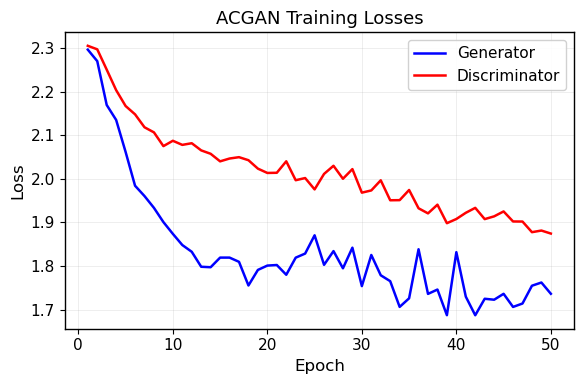


Model testing:

Image processing 1/5: pic5_2_17.png


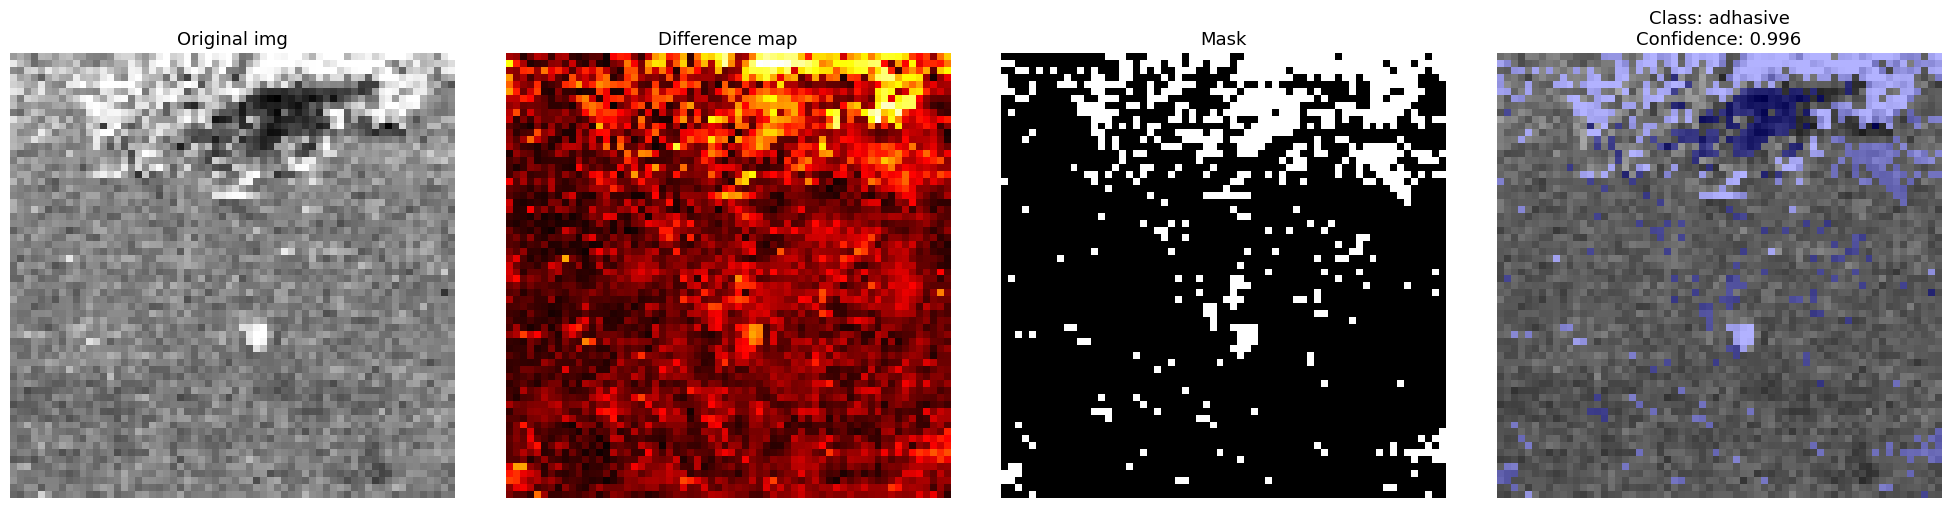

class probability:
  normal: 0.0000
  abrasive: 0.0000
  adhasive: 0.9963
  cracks: 0.0002
  delamination: 0.0035

Image processing 2/5: pic5_7_3.png


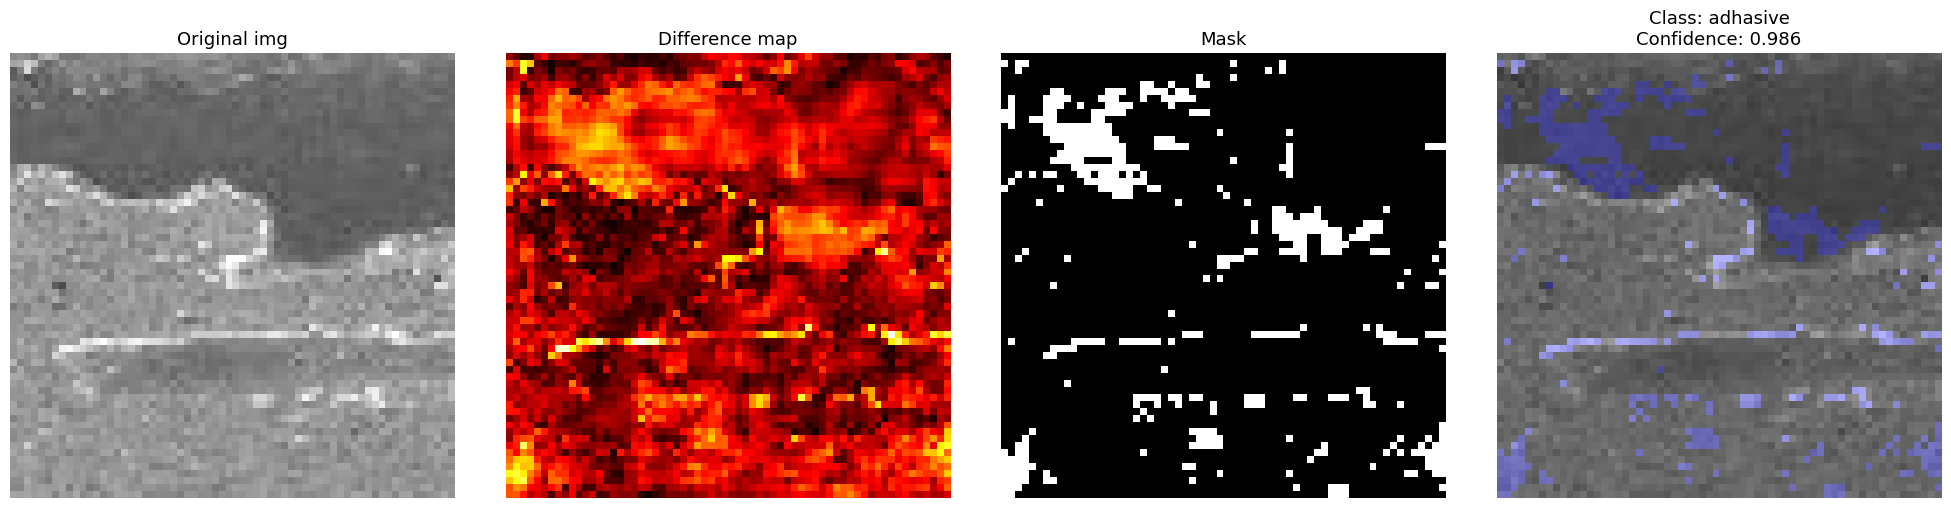

class probability:
  normal: 0.0000
  abrasive: 0.0000
  adhasive: 0.9863
  cracks: 0.0001
  delamination: 0.0136

Image processing 3/5: pic5_7_15.png


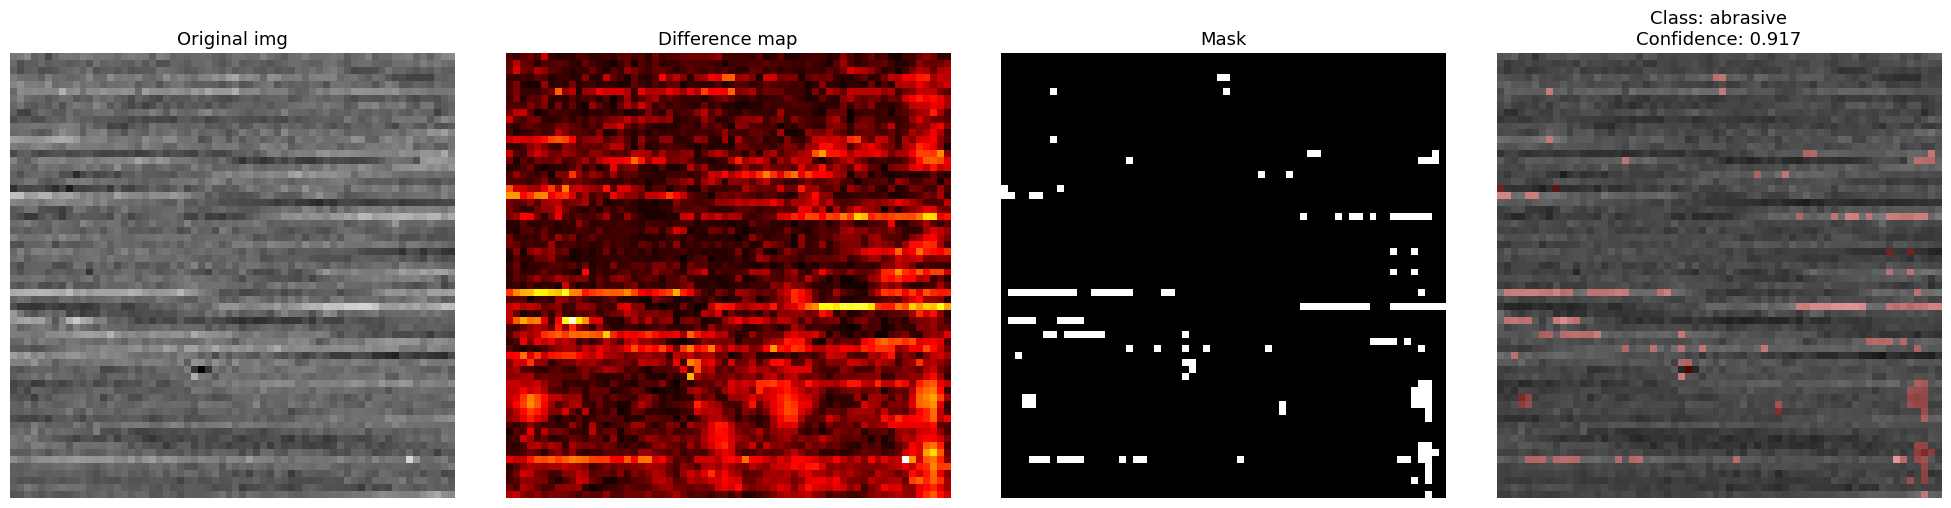

class probability:
  normal: 0.0787
  abrasive: 0.9168
  adhasive: 0.0018
  cracks: 0.0006
  delamination: 0.0021

Image processing 4/5: pic5_9_10.png


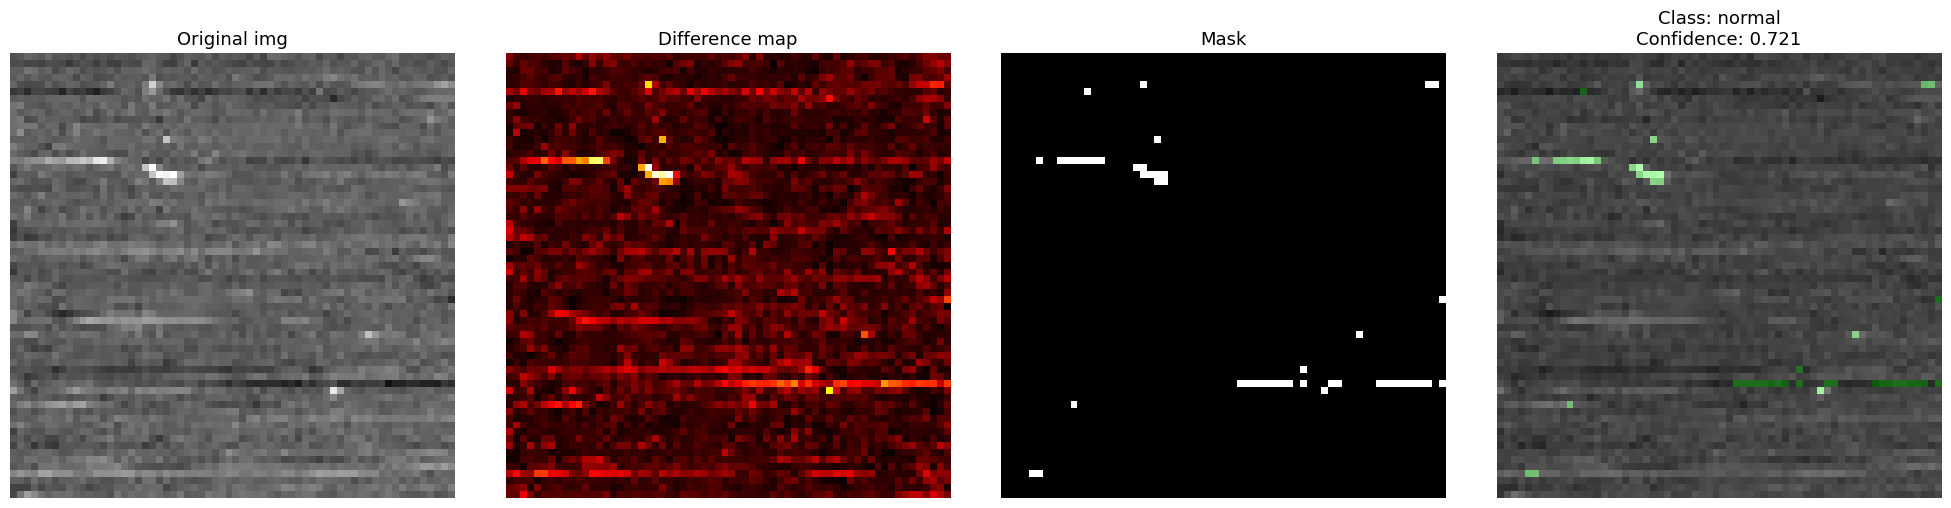

class probability:
  normal: 0.7212
  abrasive: 0.2587
  adhasive: 0.0001
  cracks: 0.0080
  delamination: 0.0120

Image processing 5/5: pic3_8_13.png


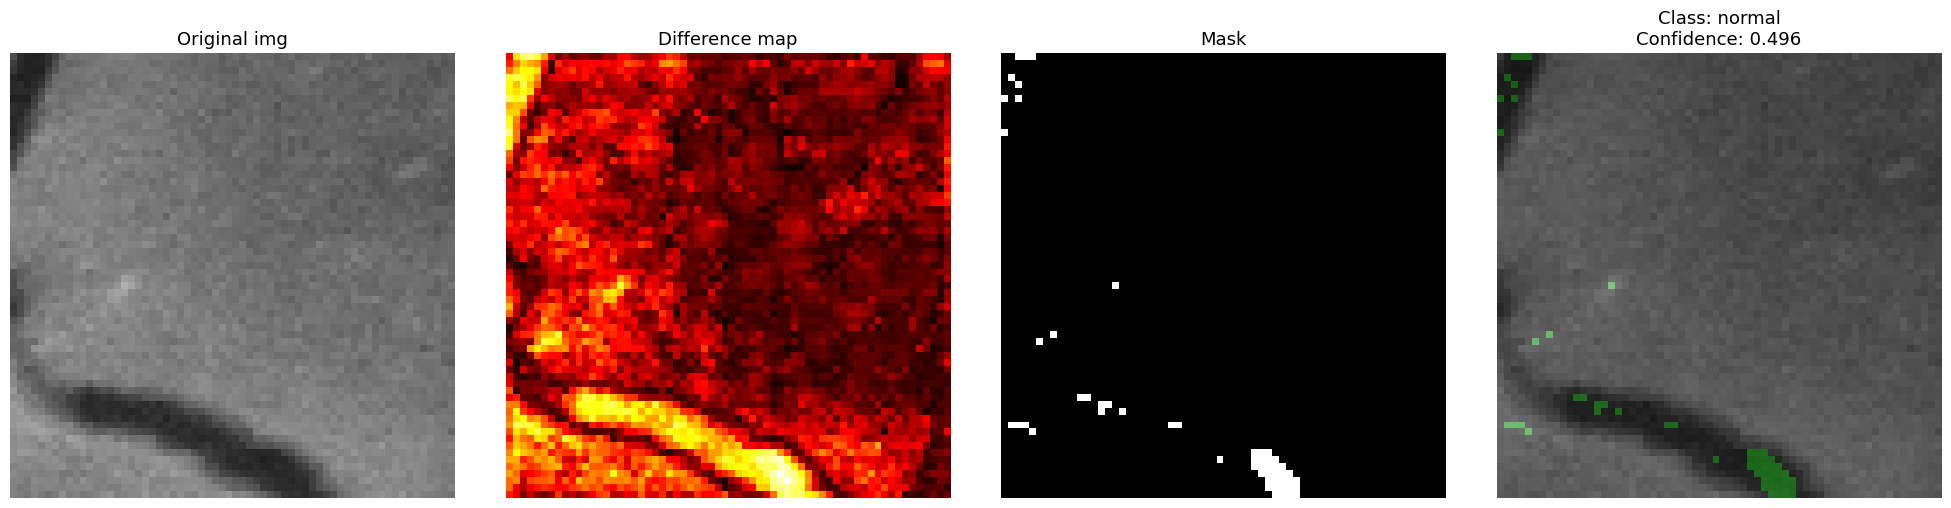

class probability:
  normal: 0.4955
  abrasive: 0.4041
  adhasive: 0.0257
  cracks: 0.0619
  delamination: 0.0128


In [5]:
def main():
    normal_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_normalimags"
    defect_folders = [
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\abrasive",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\adhesive", 
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\cracks",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\delamination"       
    ]
    test_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_abnormalimags"
    
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize([0.5] * 3, [0.5] * 3)
    ])
    
    dataset = ACGANDataset(normal_folder, defect_folders, transform)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=0)
    
    acgan = ACGANAnomalyDetection(num_classes=5, img_size=64)
    
    acgan.train(dataloader, epochs=50)
    
    torch.save({
        'generator': acgan.generator.state_dict(),
        'discriminator': acgan.discriminator.state_dict(),
    }, '2_anomaly_detection.pth')

    acgan.plot_for_paper(save_path='acgan_losses.png')

    print("\nModel testing:")
    test_images = get_random_images(test_folder, num_samples=5)
    if test_images:
        acgan.visualize_results(test_images)

def get_random_images(folder_path, num_samples=5):
    extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
    all_images = []
    
    for extension in extensions:
        all_images.extend(glob.glob(os.path.join(folder_path, extension)))
    
    if not all_images:
        return []
    
    return random.sample(all_images, min(num_samples, len(all_images)))

if __name__ == "__main__":
    main()

Loading discriminator for feature extraction...
Extracting features from your dataset...
Extracting features from images...
Processing normal...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_5916\2494443986.py:47: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location='cp

Processing abrasive...
Processing adhesive...
Processing cracks...
Processing delamination...
Extracted 150 samples with 2048 features each

=== COMPARING FEATURE SPACES ===
Creating comparison of feature space visualizations...


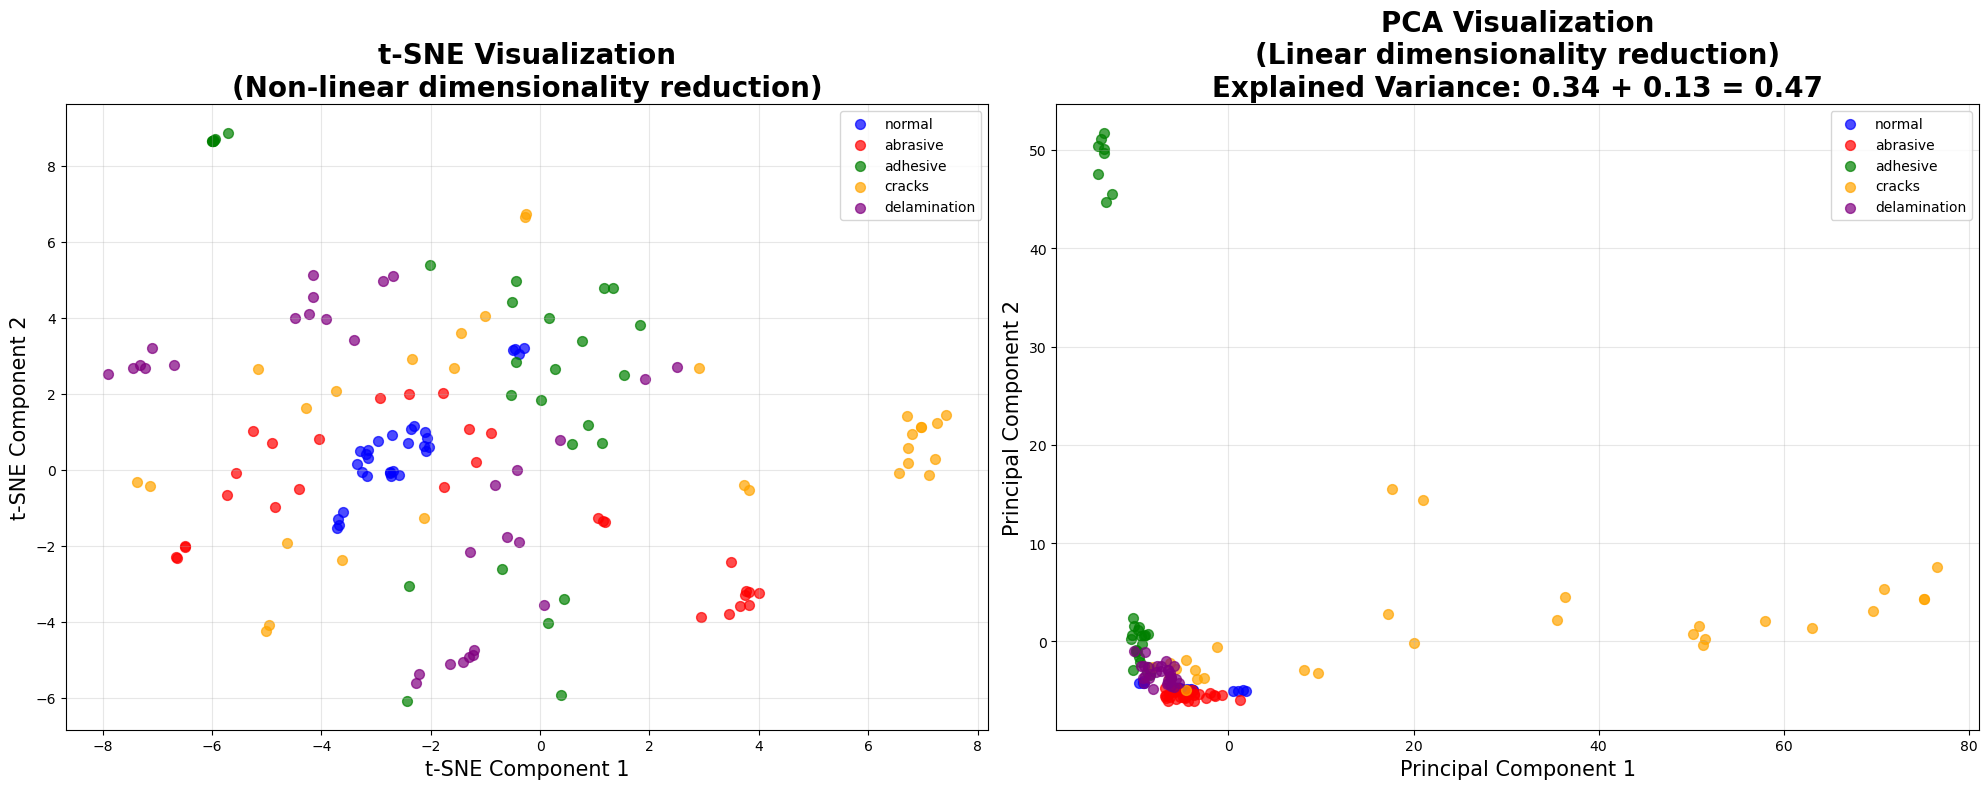


=== OUTLIER ANALYSIS ===
Found 4 potential outliers:
  pic3_11_19.png (normal): distance 3.451
  pic3_11_18.png (normal): distance 3.338
  pic3_11_17.png (normal): distance 3.301
  pic3_11_16.png (normal): distance 3.282


In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from torchvision import transforms
from PIL import Image
import os
import glob
        
class Discriminator(nn.Module):
    def __init__(self, num_classes=5):
        super(Discriminator, self).__init__()
        def block(in_f, out_f, bn=True):
            layers = [nn.Conv2d(in_f, out_f, 3, 2, 1), nn.LeakyReLU(0.2), nn.Dropout2d(0.3)]
            if bn: layers.append(nn.BatchNorm2d(out_f, 0.8))
            return layers
        
        self.model = nn.Sequential(
            *block(3, 16, bn=False),
            *block(16, 32),
            *block(32, 64), 
            *block(64, 128),
        )
        
        self.feature_size = 128 * 4 * 4  # 64x64 -> 4x4 after 4 conv layers with stride 2
        self.adv_layer = nn.Sequential(nn.Linear(self.feature_size, 1), nn.Sigmoid())
        self.aux_layer = nn.Sequential(nn.Linear(self.feature_size, num_classes), nn.Softmax(dim=1))
    
    def extract_features(self, img):
        features = self.model(img)
        features = features.view(features.size(0), -1)  # Flatten
        return features
    
    def forward(self, img):
        features = self.extract_features(img)
        validity = self.adv_layer(features)
        label = self.aux_layer(features)
        return validity, label

def load_discriminator(model_path):
    discriminator = Discriminator(num_classes=5)
    checkpoint = torch.load(model_path, map_location='cpu')
    discriminator.load_state_dict(checkpoint['discriminator'])
    discriminator.eval()
    return discriminator

def extract_features_from_images(discriminator, folder_paths, class_names, num_images_per_class=20):
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize([0.5] * 3, [0.5] * 3)
    ])
    
    all_features = []
    all_labels = []
    all_filenames = []
    
    for class_idx, folder_path in enumerate(folder_paths):
        print(f"Processing {class_names[class_idx]}...")

        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
        images = []
        for ext in extensions:
            images.extend(glob.glob(os.path.join(folder_path, ext)))

        images = images[:num_images_per_class]
        
        for img_path in images:
            try:
                img = Image.open(img_path).convert('RGB')
                img_tensor = transform(img).unsqueeze(0)
                
                with torch.no_grad():
                    features = discriminator.extract_features(img_tensor)
                
                all_features.append(features.squeeze().numpy())
                all_labels.append(class_idx)
                all_filenames.append(os.path.basename(img_path))
                
            except Exception as e:
                print(f"Error processing {img_path}: {e}")
    
    return np.array(all_features), np.array(all_labels), all_filenames

def visualize_feature_space(features, labels, filenames, class_names, method='tsne'):
    """Visualize the feature space using dimensionality reduction"""
    
    print(f"Reducing dimensions using {method.upper()}...")
    
    if method == 'tsne':
        reducer = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
        embeddings = reducer.fit_transform(features)
        title = 't-SNE Visualization of Feature Space'
    elif method == 'pca':
        reducer = PCA(n_components=2, random_state=42)
        embeddings = reducer.fit_transform(features)
        variance_ratio = reducer.explained_variance_ratio_
        title = f'PCA Visualization (Variance: {variance_ratio[0]:.2f}, {variance_ratio[1]:.2f})'
    
    plt.figure(figsize=(12, 10))

    colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        plt.scatter(embeddings[mask, 0], embeddings[mask, 1], 
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.5)
    
    plt.title(title, fontsize=16, fontweight='bold')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.legend()
    plt.grid(True, alpha=0.3)

    unique, counts = np.unique(labels, return_counts=True)
    plt.figtext(0.02, 0.02, f"Total samples: {len(features)}\n" +
               "\n".join([f"{class_names[idx]}: {count}" for idx, count in zip(unique, counts)]),
               fontsize=20, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    return embeddings

def analyze_clusters(embeddings, labels, class_names):
    """Analyze the clustering behavior"""
    from sklearn.metrics import silhouette_score, calinski_harabasz_score
    
    if len(np.unique(labels)) > 1:
        silhouette = silhouette_score(embeddings, labels)
        calinski = calinski_harabasz_score(embeddings, labels)
        
        print(f"Silhouette Score: {silhouette:.3f}")
        print(f"Calinski-Harabasz Score: {calinski:.3f}")
    
    from scipy.spatial.distance import cdist
    
    centroids = []
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        if np.sum(mask) > 0:
            centroid = np.mean(embeddings[mask], axis=0)
            centroids.append(centroid)
    
    if len(centroids) > 1:
        distances = cdist(centroids, centroids)
        np.fill_diagonal(distances, np.inf) 
        
        min_distances = np.min(distances, axis=1)
        avg_min_distance = np.mean(min_distances)
        
        print(f"Average minimum inter-class distance: {avg_min_distance:.3f}")
        
        min_idx = np.unravel_index(np.argmin(distances), distances.shape)
        max_idx = np.unravel_index(np.argmax(distances), distances.shape)
        
        print(f"Most similar classes: {class_names[min_idx[0]]} ↔ {class_names[min_idx[1]]}")
        print(f"Most different classes: {class_names[max_idx[0]]} ↔ {class_names[max_idx[1]]}")

def visualize_outliers(embeddings, labels, filenames, class_names):
    outliers = []
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        if np.sum(mask) > 1:  
            class_embeddings = embeddings[mask]
            class_filenames = [filenames[i] for i in range(len(filenames)) if labels[i] == class_idx]
            
            centroid = np.mean(class_embeddings, axis=0)
            distances = np.linalg.norm(class_embeddings - centroid, axis=1)
            
            threshold = np.mean(distances) + 2 * np.std(distances)
            outlier_indices = np.where(distances > threshold)[0]
            
            for idx in outlier_indices:
                outliers.append({
                    'filename': class_filenames[idx],
                    'class': class_names[class_idx],
                    'distance': distances[idx],
                    'embedding': class_embeddings[idx]
                })
    
    if outliers:
        print(f"Found {len(outliers)} potential outliers:")
        for outlier in sorted(outliers, key=lambda x: x['distance'], reverse=True)[:5]:  # Top 5
            print(f"  {outlier['filename']} ({outlier['class']}): distance {outlier['distance']:.3f}")
    else:
        print("No significant outliers found.")

def compare_feature_spaces(features, labels, class_names):
    print("Creating comparison of feature space visualizations...")
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
    embeddings_tsne = tsne.fit_transform(features)
    
    pca = PCA(n_components=2, random_state=42)
    embeddings_pca = pca.fit_transform(features)
    variance_ratio = pca.explained_variance_ratio_
    
    colors = ['blue', 'red', 'green', 'orange', 'purple']
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        ax1.scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50)
    
    ax1.set_title('t-SNE Visualization\n(Non-linear dimensionality reduction)', fontsize=20, fontweight='bold')
    ax1.set_xlabel('t-SNE Component 1',fontsize=15)
    ax1.set_ylabel('t-SNE Component 2',fontsize=15)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        ax2.scatter(embeddings_pca[mask, 0], embeddings_pca[mask, 1],
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50)
    
    ax2.set_title(f'PCA Visualization\n(Linear dimensionality reduction)\nExplained Variance: {variance_ratio[0]:.2f} + {variance_ratio[1]:.2f} = {variance_ratio.sum():.2f}', 
                 fontsize=20, fontweight='bold')
    ax2.set_xlabel('Principal Component 1',fontsize=15)
    ax2.set_ylabel('Principal Component 2',fontsize=15)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return embeddings_tsne, embeddings_pca

if __name__ == "__main__":
    normal_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_normalimags"
    defect_folders = [
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\abrasive",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\adhasive", 
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\cracks",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\delamination"      
    ]
    
    CLASS_NAMES = ['normal', 'abrasive', 'adhesive', 'cracks', 'delamination']
    MODEL_PATH = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\2_anomaly_detection.pth"
    
    all_folders = [normal_folder] + defect_folders

    discriminator = load_discriminator(MODEL_PATH)
    
    features, labels, filenames = extract_features_from_images(
        discriminator, all_folders, CLASS_NAMES, num_images_per_class=30
    )
    
    print(f"Extracted {len(features)} samples with {features.shape[1]} features each")

    embeddings_tsne, embeddings_pca = compare_feature_spaces(features, labels, CLASS_NAMES)
    visualize_outliers(embeddings_tsne, labels, filenames, CLASS_NAMES)